# 05 Skills and text: what do Hacker News "Who is hiring?" posts ask for?

Stream B2. Inputs (local only, git-ignored): `data/raw/hn_whoishiring_posts.csv` and `data/raw/hn_whoishiring_text.csv`
(create them with `python collect.py --sources hn`). **The raw text must not be committed or redistributed.**

**Read this before quoting any number**
- Posts come from a startup-skewed corner of the market, not from "IT jobs" in general.
- `remote`, `junior` and `ai_ml` are keyword rules **without negation handling** ("no remote", "no interns" still count). Section 5 measures how often that matters.
- The topic model (TF-IDF + NMF) depends on `k` and the seed; topics are descriptions, not categories that exist in the world.
- Everything here is association over time. A change after 2022-11-30 is not shown to be caused by ChatGPT.

In [1]:
import os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)      # the project's data paths are relative to the repo root
from collectors.common import RAW, PROCESSED, MANUAL
from analysis import hn_text as ht

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
df = ht.load_joined()
posts = ht.load_posts()
print(f"{len(posts):,} posts, {len(df):,} with text; threads {posts['month'].min():%Y-%m} to {posts['month'].max():%Y-%m} "
      f"({posts['month'].nunique()} months)")
print("posts per month: median", int(posts.groupby('month').size().median()),
      "| min", int(posts.groupby('month').size().min()))

81,495 posts, 81,495 with text; threads 2015-01 to 2026-10 (140 months)
posts per month: median 628 | min 226


## 1. Topic model (TF-IDF + NMF)
Logistics words (remote, onsite, visa, ...) are removed from the vocabulary on purpose, so topics describe *what* is built and *with what*, and do not repeat the keyword flags.

In [2]:
K = 10
shares, terms = ht.topic_model_monthly(df, k=K)
pd.set_option("display.max_colwidth", 140)
terms[["label", "top_terms"]]

,label,top_terms
0,"T1: people, make, growing","people, make, growing, ve, product, ll, small, love, customers, world"
1,"T2: data, learning, machine","data, learning, machine, machine learning, science, data science, scientists, scientist, data scientist, data scientists"
2,"T3: san, francisco, san francisco","san, francisco, san francisco, francisco ca, ca, software san, yc, sf, bay, bay area"
3,"T4: react, stack, js","react, stack, js, node, typescript, frontend, backend, aws, tech, tech stack"
4,"T5: senior, manager, product","senior, manager, product, senior software, product manager, designer, data, platform, lead, senior product"
5,"T6: development, systems, design","development, systems, design, web, skills, applications, cloud, services, technologies, knowledge"
6,"T7: ios, android, mobile","ios, android, mobile, app, ios android, apps, web, native, android ios, swift"
7,"T8: ai, ml, founding","ai, ml, founding, agents, early, models, startup, systems, stage, research"
8,"T9: rails, ruby, ruby rails","rails, ruby, ruby rails, stack ruby, rails react, stack, react, aha, postgres, end"
9,"T10: source, open source, open","source, open source, open, community, source software, project, distributed, projects, source projects, rust"


Read the table above and give the topics human names in this dictionary (topic ids start at 0). Topics without a name keep their automatic label.

saved data\processed\hn_topics_monthly.csv (1400, 3)


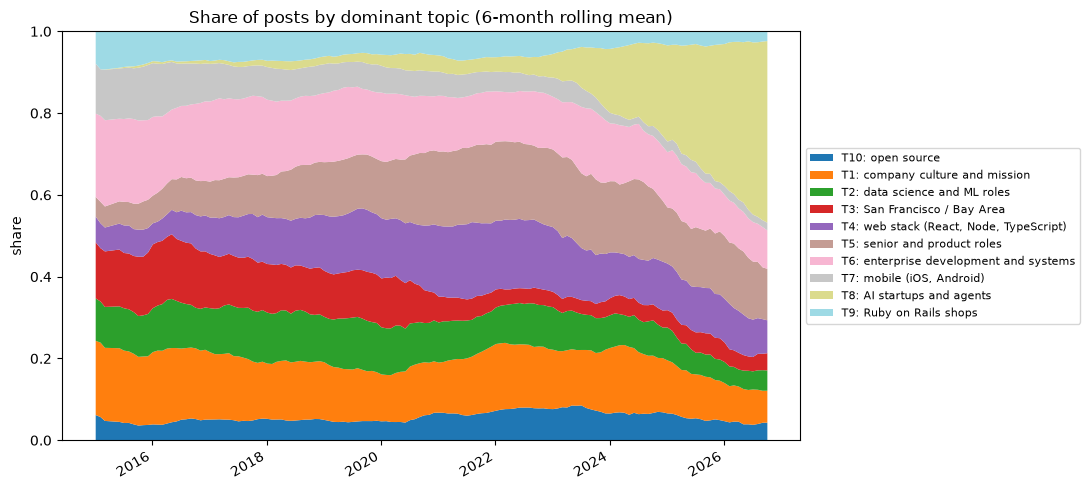

In [11]:
NAMES = {
    0: "company culture and mission",
    1: "data science and ML roles",
    2: "San Francisco / Bay Area",
    3: "web stack (React, Node, TypeScript)",
    4: "senior and product roles",
    5: "enterprise development and systems",
    6: "mobile (iOS, Android)",
    7: "AI startups and agents",
    8: "Ruby on Rails shops",
    9: "open source",
}
shares, terms = ht.topic_model_monthly(df, k=K, names=NAMES)
out = PROCESSED / "hn_topics_monthly.csv"
shares.to_csv(out, index=False)
print("saved", out, shares.shape)
wide = shares.pivot(index="month", columns="topic", values="share")
wide.index = pd.to_datetime(wide.index)
ax = wide.rolling(6, min_periods=1).mean().plot.area(figsize=(11, 5), colormap="tab20", linewidth=0)
ax.set_title("Share of posts by dominant topic (6-month rolling mean)"); ax.set_ylabel("share"); ax.set_xlabel("")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG / "05_topics_monthly.png", dpi=150); plt.show()

In [12]:
# How much do the topics depend on k? (error always falls with k; look for stable term lists, not for a minimum)
ht.reconstruction_by_k(df["text"], ks=(8, 10, 12))

,k,reconstruction_err
0,8,280.218233
1,10,279.759042
2,12,279.325207


In [13]:
# Biggest movers: topic share in the first vs the last three years
w = wide.copy()
first, last = w[w.index < w.index.min() + pd.DateOffset(years=3)].mean(), w[w.index > w.index.max() - pd.DateOffset(years=3)].mean()
(pd.DataFrame({"first_3y": first, "last_3y": last, "change_pp": (last - first) * 100}).sort_values("change_pp").round(3))

,first_3y,last_3y,change_pp
topic,,,
T3: San Francisco / Bay Area,0.136,0.044,-9.234
"T7: mobile (iOS, Android)",0.101,0.022,-7.920
T6: enterprise development and systems,0.190,0.119,-7.183
T2: data science and ML roles,0.113,0.062,-5.084
T1: company culture and mission,0.165,0.115,-4.986
T9: Ruby on Rails shops,0.074,0.029,-4.465
T10: open source,0.048,0.056,0.778
"T4: web stack (React, Node, TypeScript)",0.082,0.104,2.151
T5: senior and product roles,0.082,0.152,6.932


## 2. Change points in the remote and AI shares
Binary segmentation of the monthly mean, stopping when the gain is below 3 x the noise variance x log(n) (noise from first differences). Break months are *where the level shifts*, not exact start dates.

,start,end,months,mean_share
0,2015-01,2020-03,61,0.248
1,2020-04,2020-09,6,0.621
2,2020-10,2023-09,36,0.781
3,2023-10,2026-10,37,0.576


,start,end,months,mean_share
0,2015-01,2023-01,95,0.152
1,2023-02,2024-05,16,0.274
2,2024-06,2025-06,13,0.397
3,2025-07,2026-10,16,0.553


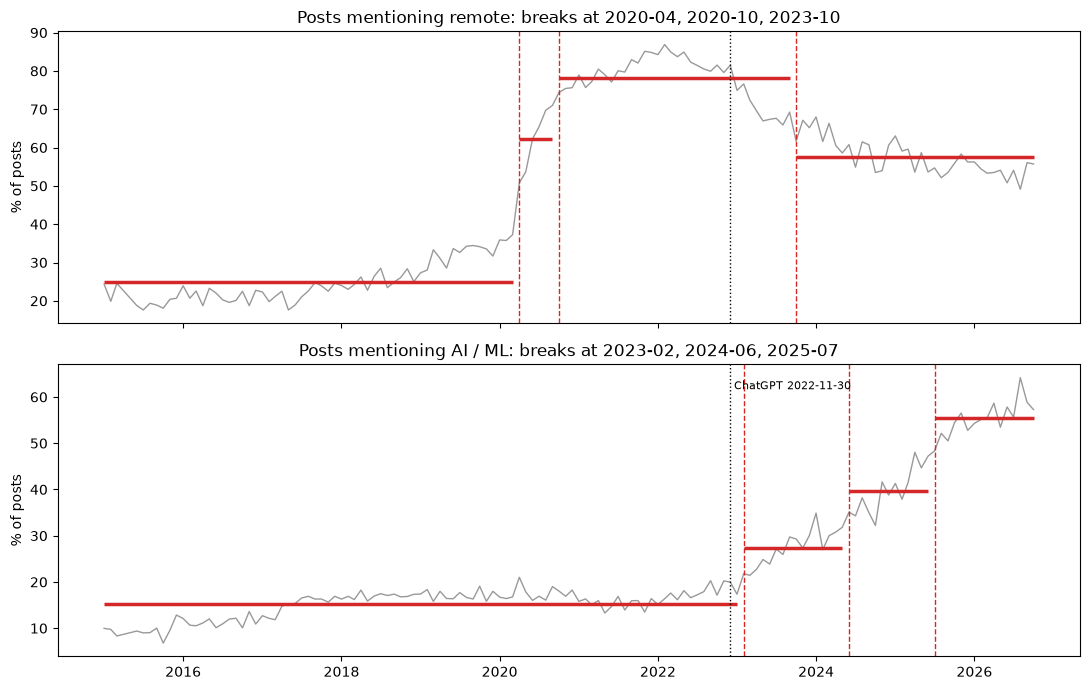

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, (flag, title) in zip(axes, [("remote", "Posts mentioning remote"), ("ai_ml", "Posts mentioning AI / ML")]):
    s = ht.monthly_share(posts, flag)
    b = ht.binary_segmentation(s.to_numpy(), n_bkps=3)
    ax.plot(s.index, s.values * 100, lw=1, color="0.6")
    edges = [0, *b, len(s)]
    for a, e in zip(edges[:-1], edges[1:]):
        ax.hlines(s.iloc[a:e].mean() * 100, s.index[a], s.index[e - 1], color="C3", lw=2.5)
    for i in b:
        ax.axvline(s.index[i], color="C3", ls="--", lw=1)
    ax.set_title(f"{title}: breaks at {', '.join(ht.break_months(s, b)) or 'none'}"); ax.set_ylabel("% of posts")
    display(ht.describe_breaks(s, b).round(3))
for ax in axes: ax.axvline(ht.CHATGPT, color="k", ls=":", lw=1)
axes[1].text(ht.CHATGPT, axes[1].get_ylim()[1] * 0.92, " ChatGPT 2022-11-30", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_change_points.png", dpi=150); plt.show()

## 3. Entry-level share, and AI mentions before / after 2022-11-30
The November 2022 thread is posted on 1 November, i.e. before ChatGPT, so threads up to 2022-11 count as "before" and 2022-12 onwards as "after".
The `pre-trend` columns extrapolate the line fitted to the months before the cutoff: if the "after" months sit near that line, nothing changed beyond the old trend.

,before_share,after_share,diff_pp,ci_low_pp,ci_high_pp,n_before,n_after,slope_pp_per_year,mean_gap_pp
flag,,,,,,,,,
ai_ml,0.152,0.391,23.906,23.092,24.721,65951,15544,0.986,19.059
junior,0.078,0.054,-2.386,-2.796,-1.975,65951,15544,-0.681,1.479


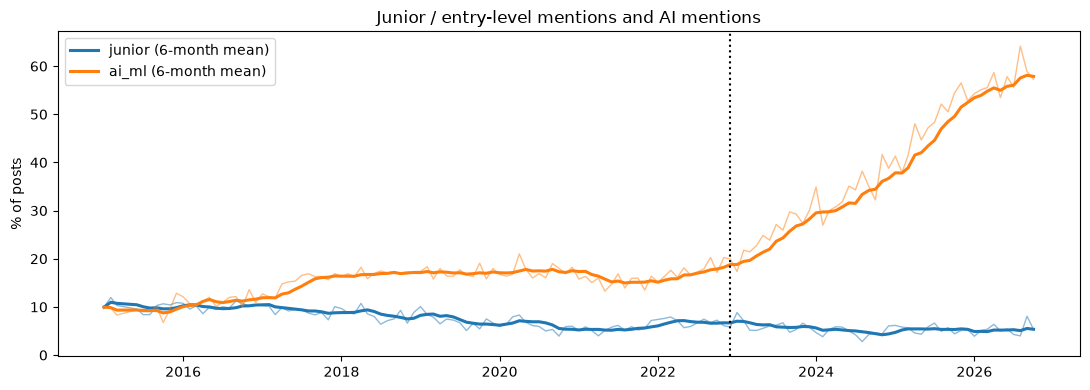

In [15]:
summary = ht.ai_summary(posts)
display(summary.round(3))
fig, ax = plt.subplots(figsize=(11, 4))
for flag, col in (("junior", "C0"), ("ai_ml", "C1")):
    s = ht.monthly_share(posts, flag) * 100
    ax.plot(s.index, s.values, color=col, lw=1, alpha=.5)
    ax.plot(s.index, s.rolling(6, min_periods=1).mean(), color=col, lw=2.2, label=f"{flag} (6-month mean)")
ax.axvline(ht.CHATGPT, color="k", ls=":"); ax.set_ylabel("% of posts"); ax.legend()
ax.set_title("Junior / entry-level mentions and AI mentions")
plt.tight_layout(); plt.savefig(FIG / "05_junior_ai.png", dpi=150); plt.show()

**Causality caution.** Junior mentions were already falling before AI (the pre-trend slope above), so a lower junior share after 2022 is
mostly the old trend continuing. AI mentions rise sharply after 2022, but they also reflect that employers began *labelling* products as AI,
that the thread population changed (more AI start-ups post here), and that "AI" is a loose keyword. None of this identifies an effect of ChatGPT on hiring.

## 4. Negation diagnostic (no hand labels needed)
A lower bound on false positives: flagged posts that contain an obvious negation next to the keyword.

In [16]:
ht.negation_diagnostic(df).round(1)

,flagged_posts,with_obvious_negation,share_pct
flag,,,
remote,37921,374,1.0
junior,5993,95,1.6


## 5. Validating the keyword flags by hand
1. Run once: `python -m analysis.hn_text sample` writes `data/manual/hn_validation_sample.csv` (100 random posts, git-ignored).
2. Fill `label_remote` and `label_junior` with 1 or 0 (guide in `make_validation_sample`'s docstring), keep the file.
3. Re-run the cell below. With about 7% junior posts expect only ~7 true positives in 100, so the **recall interval for junior is wide**; label more posts (`-n 300`, new file) if it matters.

In [17]:
path = MANUAL / "hn_validation_sample.csv"
if not path.exists():
    print("No sample yet. Run: python -m analysis.hn_text sample")
else:
    lab = pd.read_csv(path, dtype={"post_id": str}, keep_default_na=False)
    done = pd.to_numeric(lab[["label_remote", "label_junior"]].stack(), errors="coerce").notna().sum()
    if done == 0:
        print(f"{path} exists but has no labels yet: fill label_remote and label_junior with 1/0.")
    else:
        display(ht.validate_flags(lab, posts))
        m = lab.merge(posts[["post_id", "remote", "junior"]], on="post_id")
        for f in ("remote", "junior"):
            fp = m[(m[f] == 1) & (pd.to_numeric(m[f"label_{f}"], errors="coerce") == 0)]
            print(f"\n{f}: {len(fp)} false positives (first 5, first 200 characters; local use only)")
            for t in fp["text"].head(5): print("  -", t[:200].replace("\n", " "))

,labelled,true_pos,false_pos,false_neg,true_neg,precision,precision_ci,recall,recall_ci,warning
flag,,,,,,,,,,
remote,100,38,4,4,54,0.904762,"(0.779, 0.962)",0.904762,"(0.779, 0.962)",
junior,100,4,3,77,16,0.571429,"(0.25, 0.842)",0.049383,"(0.019, 0.12)",



remote: 4 false positives (first 5, first 200 characters; local use only)
  - DeviantArt | Senior Site Reliability Engineer/Senior DevOps Engineer/Senior Infrastructure Engineer | US/Canada - West Coast/Mountain Time (Fully REMOTE but must be in one of those time zones) or Tel 
  - Location: Nairobi,Kenya Remote: Yes Willing to relocate: Yes Technologies: React js, react native, C, Python, Php laravel.. Code igniter , Java, HTML, CSS, Git, MySQL..... And open to learn new techno
  - OppLoans Software Engineering Manager | Full Time | Chicago, IL (Remote until IL Phase 5 Reopening) | https://bit.ly/2CUwxEQ Software Engineer / Senior Software Engineer | Salesforce Engineering Team 
  - FAYETTEVILLE, AR | ONSITE | Frontend Developer | WEHCO Media WEHCO Media is a local media corporation. WEHCO owns several regional and state-wide publications in Arkansas, Tennessee, and Missouri, as 

junior: 3 false positives (first 5, first 200 characters; local use only)
  - Curai | Senior Machine Lea

## 6. Findings (generated from the numbers above, so they cannot drift from them)

In [18]:
rm, ai = ht.monthly_share(posts, "remote"), ht.monthly_share(posts, "ai_ml")
rb, ab = ht.break_months(rm, ht.binary_segmentation(s.to_numpy(), n_bkps=3), ht.break_months(ai, ht.binary_segmentation(ai.to_numpy()))
a, j = summary.loc["ai_ml"], summary.loc["junior"]
neg = ht.negation_diagnostic(df)
print(f"- Remote: level shifts detected at {', '.join(rb) or 'no month'}; AI/ML mentions: {', '.join(ab) or 'no month'}.")
print(f"- AI/ML mentions: {a.before_share*100:.1f}% of posts up to 2022-11 vs {a.after_share*100:.1f}% from 2022-12 "
      f"({a.diff_pp:+.1f} pp, interval {a.ci_low_pp:+.1f} to {a.ci_high_pp:+.1f}; the interval ignores clustering by month).")
print(f"- Junior mentions: {j.before_share*100:.1f}% before vs {j.after_share*100:.1f}% after ({j.diff_pp:+.1f} pp); "
      f"the pre-2022 trend was already {j.slope_pp_per_year:+.2f} pp per year, so the post-2022 level is {j.mean_gap_pp:+.1f} pp from that trend line.")
print(f"- Keyword rules: at least {neg.loc['remote','share_pct']:.1f}% of 'remote' posts and {neg.loc['junior','share_pct']:.1f}% of 'junior' posts "
      "contain an obvious negation (lower bound on false positives).")
print("- Limits: startup-skewed sample, keyword flags without negation handling, topics depend on k and the seed, association only.")

SyntaxError: '(' was never closed (1071220514.py, line 2)